# Exploratory data analysis

What the data is, where it comes from, what was wrong with it, and which findings changed how the project was built.
Each section ends with **Finding → decision**.

Run after downloading GTZAN into `data/` and generating the spectrograms and the features CSV (see the README).

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import display
from PIL import Image
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "pyproject.toml").is_file())
DATA_DIR = PROJECT_ROOT / "data"
WAV_DIR = DATA_DIR / "genres_original"
PNG_DIR = DATA_DIR / "mel_spectrograms"
CSV_PATH = DATA_DIR / "features_3_sec.csv"
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]
SEGMENT_SECONDS, SEGMENT_COUNT = 3, 10

# Chart style, same as cnn/cnn_vs_random_forest.ipynb. Jazz is highlighted, every other genre is neutral gray.
JAZZ, OTHER = "#eb6834", "#c3c2b7"
INK, INK_SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "font.size": 10,
    }
)


def genre_colors(genres):
    return [JAZZ if genre == "jazz" else OTHER for genre in genres]

## 1. Provenance

| | |
|---|---|
| Dataset | **GTZAN** (G. Tzanetakis and P. Cook, *Musical genre classification of audio signals*, IEEE TSAP 2002) |
| Where we got it | Kaggle mirror: [andradaolteanu/gtzan-dataset-music-genre-classification](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/data?select=Data) |
| Content | 1,000 audio clips of 30 s, 10 genres × 100, collected around 2000–2001 from CDs, radio and microphone recordings |
| What we use | Only the raw audio (`genres_original`). Spectrograms (`wav_to_mel_spectrograms.py`) and features (`features_to_csv.py`) are generated by our own scripts, with the same code the live filter uses on new songs |
| Change from the proposal | The proposal planned a Kaggle dataset of pre-computed mel spectrograms. Using raw audio lets the training spectrograms and the live filter's spectrograms come from the same pipeline |
| Known problems | Sturm (2013, [arXiv:1306.1461](https://arxiv.org/abs/1306.1461)) documents repeated clips, mislabeled clips, distorted recordings and many clips per artist |

## 2. Inventory and integrity

Every `.wav` file is opened and its format checked. The audio of each file is hashed to detect exact duplicates.

In [2]:
rows = []
for path in sorted(WAV_DIR.rglob("*.wav")):
    row = {"genre": path.parent.name, "song": path.stem.replace(".", ""), "file": path.name}
    try:
        info = sf.info(path)
        audio, _ = sf.read(path, dtype="int16")
        row.update(
            readable=True,
            sample_rate=info.samplerate,
            channels=info.channels,
            subtype=info.subtype,
            duration=info.duration,
            md5=hashlib.md5(audio.tobytes()).hexdigest(),
        )
    except Exception as error:
        row.update(readable=False, error=f"{type(error).__name__}: {error}")
    rows.append(row)
wavs = pd.DataFrame(rows)
readable = wavs[wavs["readable"]].copy()

print(f"{len(wavs)} files, {len(readable)} readable")
display(wavs.loc[~wavs["readable"], ["file", "genre", "error"]])
display(readable[["sample_rate", "channels", "subtype"]].value_counts().rename("files").to_frame())

1000 files, 999 readable


,file,genre,error
554,jazz.00054.wav,jazz,LibsndfileError: Error opening '/Users/philip/...


,,,files
sample_rate,channels,subtype,
22050.0,1.0,PCM_16,999


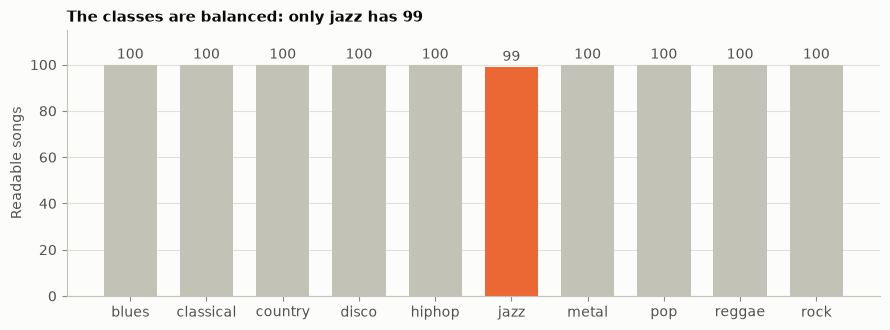

In [3]:
counts = readable["genre"].value_counts().reindex(GENRES)
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(GENRES, counts.values, color=genre_colors(GENRES), width=0.7)
ax.bar_label(bars, color=INK_SECONDARY, padding=2)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Readable songs")
short = counts[counts < counts.max()]
title = "The classes are balanced"
if len(short):
    title += ": only " + ", ".join(f"{g} has {n}" for g, n in short.items())
ax.set_title(title)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Finding → decision.** One jazz file can't be decoded, so it is excluded (`excluded_audios` in
`validate_dataset.py`) and jazz has 99 songs. Every other file has the same format. The classes are balanced, so plain
accuracy is a fair summary across the 10 genres, and every split is **stratified** by genre so each one keeps that
balance. The jazz filter itself is judged on precision and recall of jazz (README, *Framing*), not on accuracy.

In [4]:
duplicates = readable[readable.duplicated("md5", keep=False)].sort_values(["md5", "song"])
pairs = duplicates.groupby("md5").agg(songs=("song", list), genres=("genre", list))
pairs["same genre"] = pairs["genres"].apply(lambda g: len(set(g)) == 1)
print(f"{len(duplicates)} files form {len(pairs)} groups of byte-identical audio")
display(pairs.reset_index(drop=True))

# Did a copy end up in training while the other one is in the test set? Both models use the same split.
with open(PROJECT_ROOT / "models" / "cnn.json", encoding="utf-8") as f:
    test_songs = set(json.load(f)["split"]["test_songs"])
pairs["test side"] = pairs["songs"].apply(lambda s: [x for x in s if x in test_songs])
leaking = pairs[pairs["test side"].apply(len).between(1, pairs["songs"].apply(len).max() - 1)]
print(f"Test songs with an identical copy in training: {sum(len(s) for s in leaking['test side'])} of {len(test_songs)}")
display(leaking[["songs", "genres", "test side"]].reset_index(drop=True))

28 files form 14 groups of byte-identical audio


,songs,genres,same genre
0,"[metal00041, metal00062]","[metal, metal]",True
1,"[disco00098, disco00099]","[disco, disco]",True
2,"[reggae00081, reggae00082]","[reggae, reggae]",True
3,"[pop00054, pop00060]","[pop, pop]",True
4,"[metal00040, metal00061]","[metal, metal]",True
5,"[metal00045, metal00066]","[metal, metal]",True
6,"[metal00042, metal00063]","[metal, metal]",True
7,"[hiphop00076, hiphop00078]","[hiphop, hiphop]",True
8,"[metal00034, metal00094]","[metal, metal]",True
9,"[metal00043, metal00064]","[metal, metal]",True


Test songs with an identical copy in training: 6 of 200


,songs,genres,test side
0,"[pop00054, pop00060]","[pop, pop]",[pop00060]
1,"[metal00034, metal00094]","[metal, metal]",[metal00034]
2,"[metal00043, metal00064]","[metal, metal]",[metal00064]
3,"[pop00067, pop00071]","[pop, pop]",[pop00067]
4,"[metal00044, metal00065]","[metal, metal]",[metal00044]
5,"[metal00058, rock00016]","[metal, rock]",[rock00016]


**Finding → decision.** GTZAN contains **byte-identical copies**: 14 pairs, most of them metal, and one pair with
**two different labels** (`metal00058` and `rock00016` are the same audio). We found them in this EDA, **after** the
models were trained, so they were not removed. Their effect on the reported results:

- **6 of the 200 test songs have an identical copy in training.** For 5 of them (pop and metal) the model has
  effectively seen the answer, so song accuracy is inflated by up to 5 / 200 = **2.5 points**. The sixth, `rock00016`,
  is in the test set while its copy is in training labeled *metal*: a contradictory label, not a free answer.
- **None of the duplicates is jazz**, so jazz recall is unaffected; for the false-pass rate (non-jazz songs kept) they
  change the denominator by a few songs out of 180.
- For a retraining, the copies should be removed first (keep one of each pair, drop the contradictory pair).

This hash only catches *exact* copies. Sturm (2013) also reports repetitions that are not byte-identical and many clips
by the same artist, which this check can't see: one more reason the holdout results are **probably optimistic**.

## 3. Duration

Each song is cut into exactly 10 segments of 3 s (`librosa.util.fix_length` in `wav_to_mel_spectrograms.py` and
`features_to_csv.py`): a file shorter than 30 s gets silence at the end, a longer one loses its tail.

Duration: min 29.93 s, median 30.01 s, max 30.65 s
Shorter than 30 s (padded with silence): 4 files, at most 0.07 s
Longer than 30 s (tail cut): 694 files, at most 0.65 s


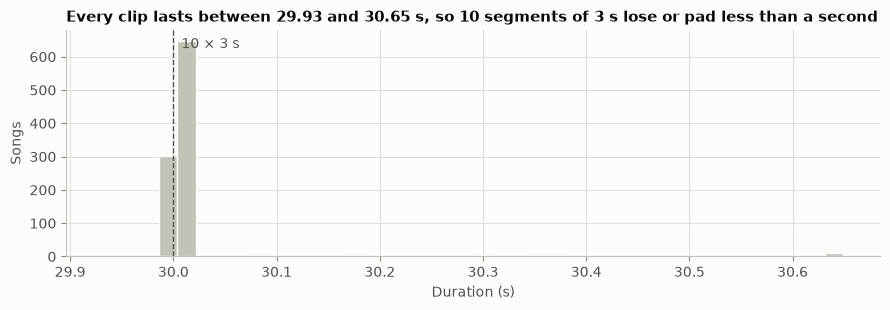

In [5]:
target = SEGMENT_COUNT * SEGMENT_SECONDS
readable["padding_seconds"] = (target - readable["duration"]).clip(lower=0)
readable["cut_seconds"] = (readable["duration"] - target).clip(lower=0)
print(f"Duration: min {readable['duration'].min():.2f} s, median {readable['duration'].median():.2f} s, "
      f"max {readable['duration'].max():.2f} s")
print(f"Shorter than 30 s (padded with silence): {(readable['padding_seconds'] > 0.005).sum()} files, "
      f"at most {readable['padding_seconds'].max():.2f} s")
print(f"Longer than 30 s (tail cut): {(readable['cut_seconds'] > 0.005).sum()} files, "
      f"at most {readable['cut_seconds'].max():.2f} s")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(readable["duration"], bins=40, color=OTHER, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(target, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(target, ax.get_ylim()[1] * 0.92, "  10 × 3 s", color=INK_SECONDARY)
ax.set_xlabel("Duration (s)")
ax.set_ylabel("Songs")
ax.set_title(f"Every clip lasts between {readable['duration'].min():.2f} and {readable['duration'].max():.2f} s, "
             "so 10 segments of 3 s lose or pad less than a second")
plt.tight_layout()
plt.show()

**Finding → decision.** The clips are uniform: at most a fraction of a second is cut or padded, so every song becomes
**exactly 10 segments of 3 s** with no further cleaning, and `validate_dataset.py` fails on any file outside 29–31 s
so a broken download can't slip in. The 3 s segment, in turn, fixes how the live filter works: it can't classify a
whole song at once, it classifies 3 s segments and averages them, like in training.

## 4. Silent and near-silent segments

A segment with almost no sound carries no information about its genre but still has the song's label.
`rms_mean` (loudness) from the features CSV finds them.

9990 segments, 999 songs, 57 features per segment
Segments with rms_mean < 0.005: 24 (0.2%) from 13 songs


label,classical
quiet segments,24


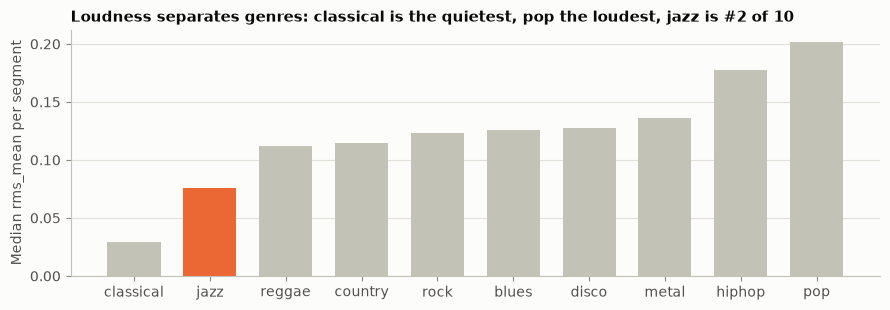

In [6]:
features = pd.read_csv(CSV_PATH)
features["song"] = features["filename"].str[:-3]
features["segment"] = features["filename"].str[-3:].astype(int)
feature_columns = [c for c in features.columns if c not in ("filename", "length", "label", "song", "segment")]
print(f"{len(features)} segments, {features['song'].nunique()} songs, {len(feature_columns)} features per segment")

quiet_threshold = 0.005
quiet = features[features["rms_mean"] < quiet_threshold]
print(f"Segments with rms_mean < {quiet_threshold}: {len(quiet)} "
      f"({len(quiet) / len(features):.1%}) from {quiet['song'].nunique()} songs")
display(quiet["label"].value_counts().rename("quiet segments").to_frame().T)

loudness = features.groupby("label")["rms_mean"].median().reindex(GENRES).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(loudness.index, loudness.values, color=genre_colors(loudness.index), width=0.7)
ax.set_ylabel("Median rms_mean per segment")
ax.set_title(f"Loudness separates genres: {loudness.index[0]} is the quietest, {loudness.index[-1]} the loudest, "
             f"jazz is #{list(loudness.index).index('jazz') + 1} of 10")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Finding → decision.** All the near-silent segments are **classical** (soft passages are part of that music), so they
are **kept**: removing them would only teach the model that classical is never quiet. No jazz segment is near-silent.

Loudness on its own separates genres, and **jazz is the second quietest**. That is a risk for real use: how loud a new
song is depends on how it was mastered, and modern masters are much louder than GTZAN's 2000-era clips. The CNN is
protected from it because each spectrogram is scaled in decibels **relative to its own maximum** (`ref=np.max` in
`_render_spectrogram`), so it sees the shape of the sound, not its absolute volume. The random forest's features
(`rms_mean`, `rms_var`) use **absolute** loudness. A plausible, *untested* explanation of why the random forest keeps
only 52% of the 73 external jazz recordings (most of them modern, loud masters) against the CNN's 85%.

## 5. The unit of analysis is the song, not the segment

Every song produces 10 segments. If segments from the same song can land in both train and test, the model can
recognise *the song* instead of learning *the genre*. The check below finds, for every segment, its nearest
neighbour in the 57-feature space (standardised) and asks whether it comes from the same song.

Nearest neighbour is another segment of the SAME SONG: 71.1% (chance: 0.09%)
Nearest neighbour is from the same genre: 92.4%


,accuracy,std
Random split by segment (leaks songs),0.912,0.008
Split by song,0.645,0.014


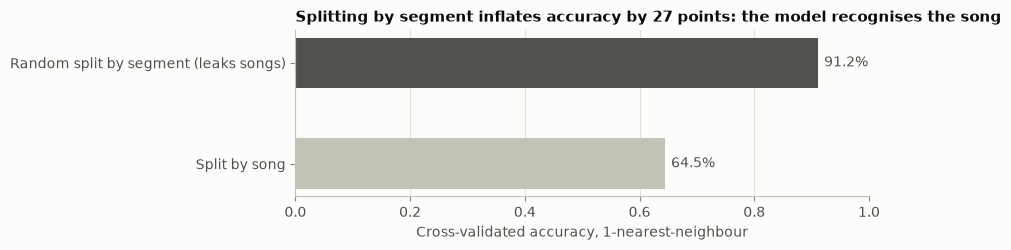

In [7]:
X = StandardScaler().fit_transform(features[feature_columns])
_, neighbours = NearestNeighbors(n_neighbors=2).fit(X).kneighbors(X)
nearest = neighbours[:, 1]
same_song = (features["song"].values[nearest] == features["song"].values).mean()
same_genre = (features["label"].values[nearest] == features["label"].values).mean()
chance = (SEGMENT_COUNT - 1) / (len(features) - 1)
print(f"Nearest neighbour is another segment of the SAME SONG: {same_song:.1%} (chance: {chance:.2%})")
print(f"Nearest neighbour is from the same genre: {same_genre:.1%}")

# The same simple model (1-nearest-neighbour), evaluated two ways.
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
y, groups = features["label"], features["song"]
by_segment = cross_val_score(model, features[feature_columns], y, cv=KFold(5, shuffle=True, random_state=42))
by_song = cross_val_score(model, features[feature_columns], y, cv=GroupKFold(5), groups=groups)
split_check = pd.DataFrame(
    {"accuracy": [by_segment.mean(), by_song.mean()], "std": [by_segment.std(), by_song.std()]},
    index=["Random split by segment (leaks songs)", "Split by song"],
)
display(split_check.round(3))

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(split_check.index[::-1], split_check["accuracy"][::-1], color=[OTHER, INK_SECONDARY], height=0.5)
for i, value in enumerate(split_check["accuracy"][::-1]):
    ax.text(value + 0.01, i, f"{value:.1%}", va="center", color=INK_SECONDARY)
ax.set_xlim(0, 1)
ax.set_xlabel("Cross-validated accuracy, 1-nearest-neighbour")
gap = by_segment.mean() - by_song.mean()
ax.set_title(f"Splitting by segment inflates accuracy by {gap * 100:.0f} points: the model recognises the song")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Finding → decision.** This is the finding that shaped the whole evaluation. Every split in the project is made **by
song** with `StratifiedGroupKFold` (holdout test set, the random forest's cross-validation and the CNN's validation
split), so all 10 segments of a song are always on the same side. The filter also decides per **song**, averaging its
segments, which is why the comparison notebook reports song-level results.

The same logic applies one level up: many GTZAN clips share an **artist**, and the split by song doesn't keep an
artist on one side. GTZAN doesn't come with artist labels, so we couldn't group by artist; this is listed as a limit.

## 6. What the model sees: mel spectrograms

One spectrogram per genre (the middle segment of the first song), exactly as the CNN receives them: time on the
horizontal axis, frequency on the vertical axis (low at the bottom), loudness as color.

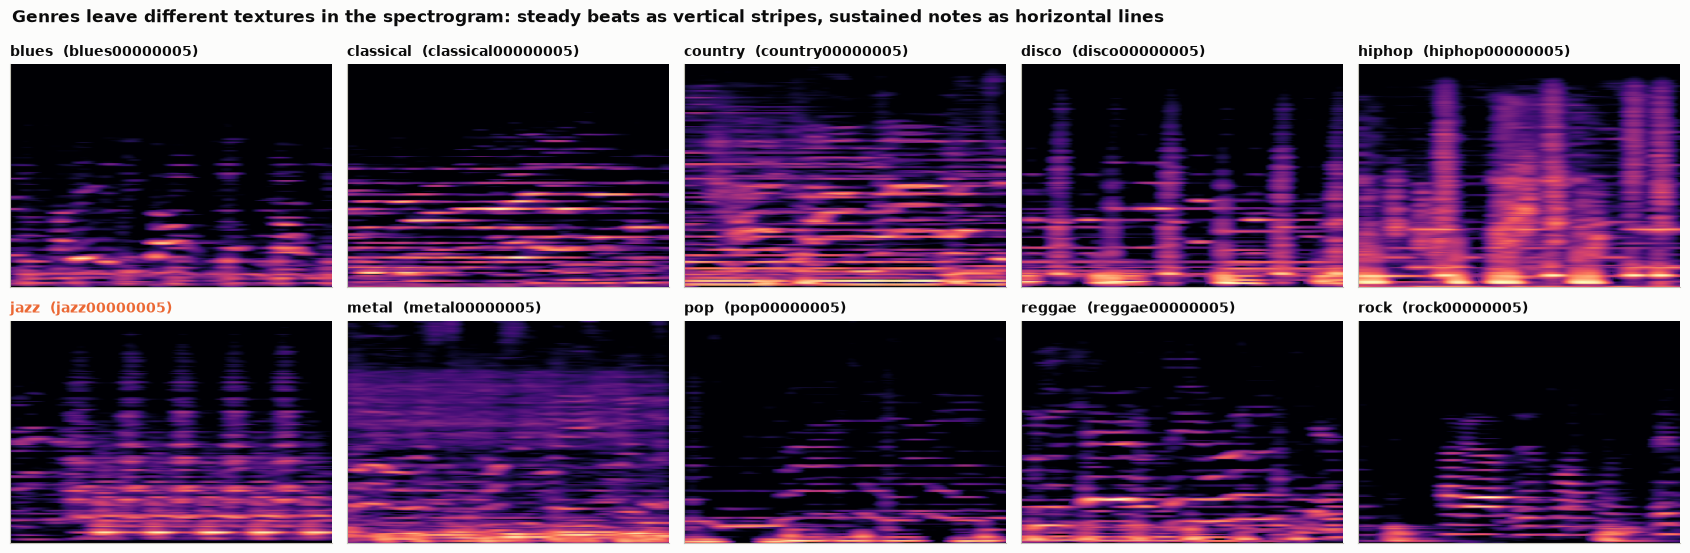

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(17, 5.6))
for ax, genre in zip(axes.flat, GENRES):
    path = sorted((PNG_DIR / genre).glob("*.png"))[SEGMENT_COUNT // 2]
    ax.imshow(Image.open(path), aspect="auto")
    ax.set_title(f"{genre}  ({path.stem})", color=JAZZ if genre == "jazz" else INK, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Genres leave different textures in the spectrogram: steady beats as vertical stripes, sustained "
             "notes as horizontal lines", x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

**Finding → decision.** The differences between genres are local visual patterns: rhythm as vertical stripes (disco,
hiphop), sustained notes as horizontal bands (classical), energy spread across frequencies (metal). Local patterns that
can appear anywhere in the image are what convolutional filters detect, which supports the proposal's choice of a
**CNN on spectrogram images** as the main model, with the random forest on hand-made features as plan B.

## 7. How jazz differs from the other genres, and where it overlaps

For each feature, the difference between the jazz songs and all other songs in standard deviations (effect size).
Then, the distance between the average jazz song and the average song of each other genre. Both use one row per song
(the mean of its 10 segments), so long songs don't count more.

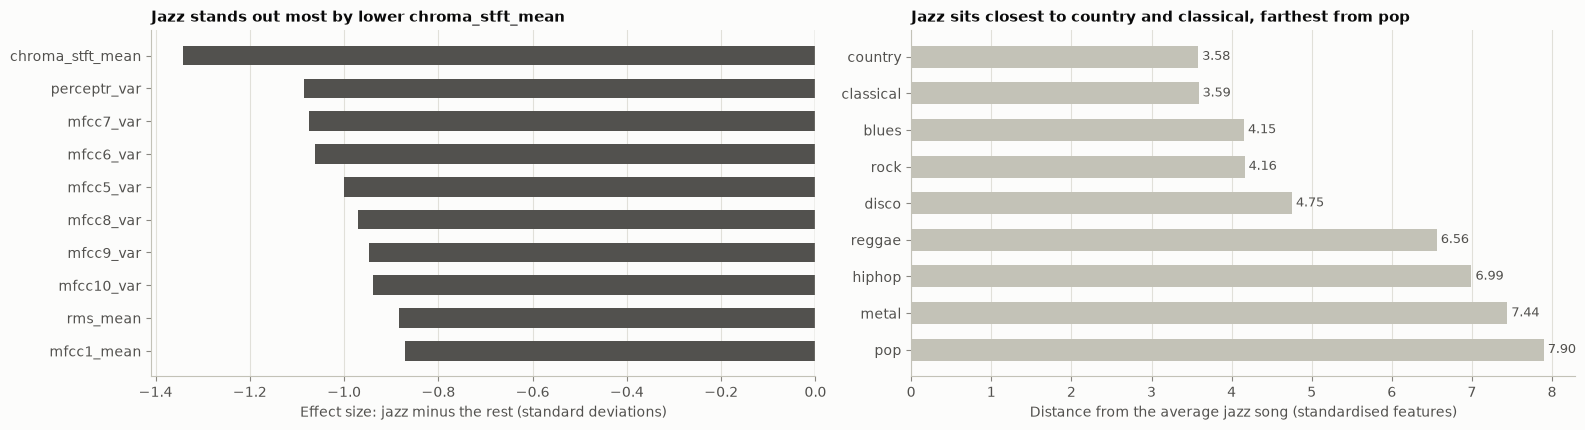

,chroma_stft_mean,perceptr_var,mfcc7_var,mfcc6_var,mfcc5_var,mfcc8_var,mfcc9_var,mfcc10_var,rms_mean,mfcc1_mean
effect size (jazz - rest),-1.34,-1.09,-1.08,-1.06,-1.0,-0.97,-0.95,-0.94,-0.88,-0.87


In [9]:
songs = features.groupby("song").agg({**{c: "mean" for c in feature_columns}, "label": "first"})
scaled = pd.DataFrame(StandardScaler().fit_transform(songs[feature_columns]), index=songs.index, columns=feature_columns)
is_jazz = songs["label"] == "jazz"
pooled_std = np.sqrt((scaled[is_jazz].var() + scaled[~is_jazz].var()) / 2)
effect = ((scaled[is_jazz].mean() - scaled[~is_jazz].mean()) / pooled_std).sort_values(key=abs, ascending=False)
top = effect.head(10)[::-1]

centroids = scaled.groupby(songs["label"]).mean()
distance = np.sqrt(((centroids - centroids.loc["jazz"]) ** 2).sum(axis=1)).drop("jazz").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
ax = axes[0]
ax.barh(top.index, top.values, color=[JAZZ if v > 0 else INK_SECONDARY for v in top.values], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("Effect size: jazz minus the rest (standard deviations)")
direction = "lower" if top.iloc[-1] < 0 else "higher"
ax.set_title(f"Jazz stands out most by {direction} {top.index[-1]}")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(distance.index[::-1], distance.values[::-1], color=OTHER, height=0.6)
for i, value in enumerate(distance.values[::-1]):
    ax.text(value + 0.05, i, f"{value:.2f}", va="center", color=INK_SECONDARY, fontsize=9)
ax.set_xlabel("Distance from the average jazz song (standardised features)")
ax.set_title(f"Jazz sits closest to {distance.index[0]} and {distance.index[1]}, farthest from {distance.index[-1]}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

display(effect.head(10).round(2).rename("effect size (jazz - rest)").to_frame().T)

**Finding → decision.** Compared with the rest, jazz is **quieter, less percussive** (`perceptr_var`), has **steadier
timbre** (lower variance of the MFCCs) and **pitch energy spread over more notes** (lower `chroma_stft_mean`, consistent
with richer harmony).

The genres closest to jazz, **country, classical and blues**, are exactly the labels of the filter's real mistakes:
Chega de Saudade (bossa nova) came out as *country*, 'Round Midnight and West End Blues as *classical*, The Girl from
Ipanema as *blues*; and *country* is the most common wrong label in the random forest's external jazz results. So
these are the confusions to expect and to **monitor in deployment** (README, *What we would monitor*). The filter keeps
a song only when jazz is the single most likely genre; trading recall for precision with a threshold on the jazz
probability would have to be tuned on validation data, not on the test set, and is left as next step.

## Summary: findings that changed the project

**Decisions the data changed or confirmed**

| Finding | Decision |
|---|---|
| One jazz file (`jazz00054`) can't be decoded | Excluded; jazz has 99 songs |
| Classes are balanced (≈100 songs each) | Stratified splits; accuracy is fair across genres; the jazz filter is judged on precision/recall of jazz |
| Clips last 29.93–30.65 s | Every song is exactly 10 segments of 3 s; `validate_dataset.py` rejects files outside 29–31 s; the live filter also classifies 3 s segments |
| A segment's nearest neighbour is another segment of the **same song** 71% of the time; splitting by segment inflates accuracy by 27 points | Every split is by song (`StratifiedGroupKFold`); decisions and results are per song |
| Near-silent segments are all classical | Kept |
| Genre differences are local textures in the spectrogram | Supports the CNN on spectrograms as the main model (random forest as plan B) |

**Found after training: limits, not decisions**

| Finding | What it means |
|---|---|
| 14 pairs of byte-identical clips, one with two labels (metal / rock) | 6 of 200 test songs have a copy in training: song accuracy inflated by up to 2.5 points; none is jazz. Remove them before retraining |
| Jazz is the second quietest genre; the random forest uses absolute loudness | Possible (untested) reason the random forest keeps only 52% of external jazz vs the CNN's 85% |
| Jazz sits closest to country, classical and blues | Those are the labels of the filter's real mistakes: what to monitor; a jazz-probability threshold would need validation data |
| GTZAN has no artist labels and repeats artists (Sturm 2013) | Couldn't split by artist: holdout results are probably optimistic |